# Prédire le coût d'une assurance santé à partir du profil de l'assuré

Projet du cours d'introduction au traitement de données (Polytech Nice Sophia).

**Question :** comment les caractéristiques d'une personne (âge, sexe, IMC, nombre d'enfants,
tabagisme, région) déterminent-elles le prix de son assurance santé ? Et peut-on trouver une
relation mathématique simple pour le prédire ?

Données : *Medical Cost Personal Dataset* (Kaggle). La monnaie et le pays ne sont pas précisés ;
on suppose qu'il s'agit des États-Unis, en dollars.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

os.makedirs("figures", exist_ok=True)
FUMEUR, NON_FUMEUR = "#c0392b", "#2e86c1"

df = pd.read_csv("data/insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Les données

In [2]:
print("lignes :", len(df), "| variables :", df.shape[1])
print("valeurs manquantes :", df.isna().sum().sum())
print("doublons :", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("observations distinctes :", len(df))

lignes : 1338 | variables : 7
valeurs manquantes : 0
doublons : 1
observations distinctes : 1337


| Variables | Type | Rôle |
|---|---|---|
| âge, IMC, nombre d'enfants | numériques | explicatives |
| sexe, tabac, région | catégorielles | explicatives |
| charges | continue | cible |

## Exploration

Une variable écrase toutes les autres : le **tabac**.

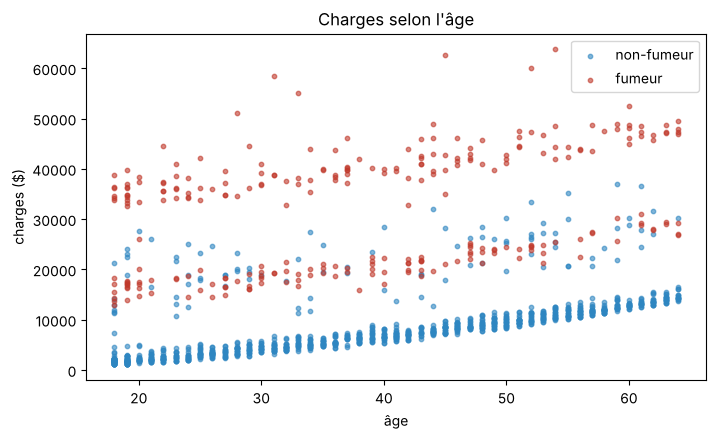

smoker
no      8441.0
yes    32050.0
Name: charges, dtype: float64


In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for fumeur, couleur, nom in [("no", NON_FUMEUR, "non-fumeur"), ("yes", FUMEUR, "fumeur")]:
    d = df[df.smoker == fumeur]
    ax.scatter(d.age, d.charges, s=10, alpha=0.6, color=couleur, label=nom)
ax.set_xlabel("âge"); ax.set_ylabel("charges ($)"); ax.legend()
ax.set_title("Charges selon l'âge")
plt.show()

print(df.groupby("smoker").charges.mean().round(0))

Un fumeur paie en moyenne presque quatre fois plus qu'un non-fumeur. Dans la suite, on regarde
toujours les deux groupes séparément.

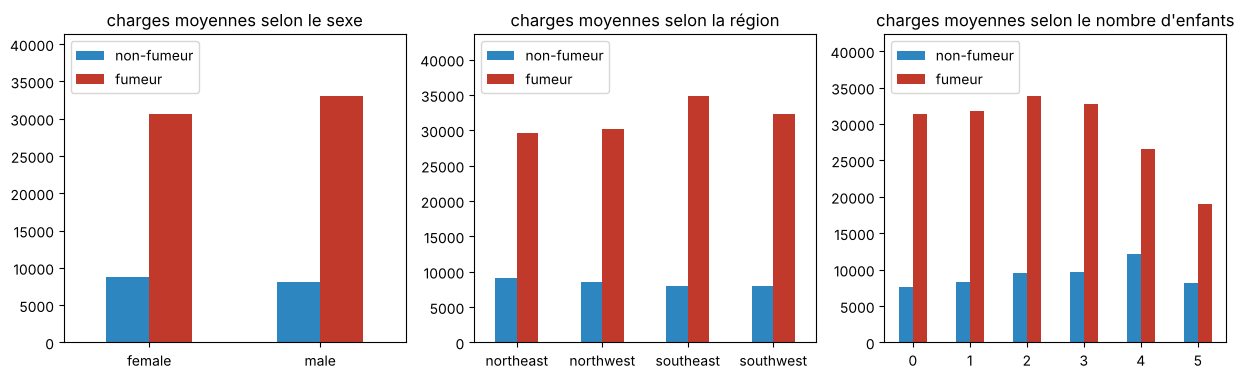

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, titre in zip(axes, ["sex", "region", "children"], ["sexe", "région", "nombre d'enfants"]):
    moyennes = df.groupby([col, "smoker"]).charges.mean().unstack()
    moyennes.plot(kind="bar", ax=ax, rot=0, color=[NON_FUMEUR, FUMEUR])
    ax.set_title(f"charges moyennes selon le {titre}" if col != "region" else "charges moyennes selon la région")
    ax.set_xlabel("")
    ax.legend(["non-fumeur", "fumeur"], loc="upper left")
    ax.set_ylim(0, moyennes.values.max() * 1.25)
plt.show()

- Le **sexe** et la **région** changent peu le prix.
- Le **nombre d'enfants** le fait légèrement monter chez les non-fumeurs.
- L'**âge** le fait monter régulièrement pour tout le monde (premier graphique).

Reste l'**IMC**, qui a un effet surprenant :

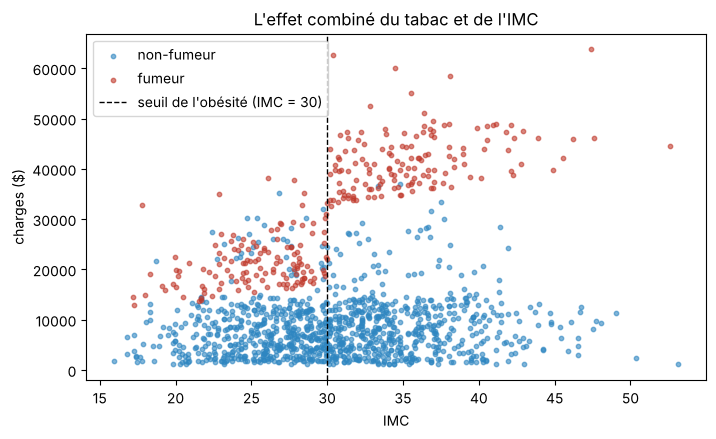

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for fumeur, couleur, nom in [("no", NON_FUMEUR, "non-fumeur"), ("yes", FUMEUR, "fumeur")]:
    d = df[df.smoker == fumeur]
    ax.scatter(d.bmi, d.charges, s=10, alpha=0.6, color=couleur, label=nom)
ax.axvline(30, color="k", ls="--", lw=1, label="seuil de l'obésité (IMC = 30)")
ax.set_xlabel("IMC"); ax.set_ylabel("charges ($)")
ax.set_title("L'effet combiné du tabac et de l'IMC")
ax.legend(loc="upper left")
plt.show()

Chez les non-fumeurs, l'IMC ne change presque rien. Chez les fumeurs, les charges font un saut au
seuil de l'obésité : le tabac et l'obésité ne s'additionnent pas, ils se **multiplient**.

## Variables créées

Pour les modèles, on transforme les variables :

- **sexe** et **tabac** en 0 / 1 ;
- **IMC** en catégorie binaire : obèse (IMC ≥ 30) ou non ;
- **région** en 4 catégories (une colonne de 0 / 1 par région, moins une prise comme référence).

En croisant tabac et obésité, on obtient un profil de risque :

In [6]:
df["femme"] = (df.sex == "female").astype(int)
df["fumeur"] = (df.smoker == "yes").astype(int)
df["obese"] = (df.bmi >= 30).astype(int)

profils = df.groupby(["fumeur", "obese"]).charges.agg(["count", "mean"]).round(0)
profils.index = ["non-fumeur, IMC < 30", "non-fumeur, IMC ≥ 30", "fumeur, IMC < 30", "fumeur, IMC ≥ 30"]
profils.columns = ["nombre", "charges moyennes ($)"]
print(profils)
print(f"\ncorrélation avec les charges : tabac seul {np.corrcoef(df.fumeur, df.charges)[0, 1]:.3f}"
      f" | fumeur et obèse {np.corrcoef(df.fumeur * df.obese, df.charges)[0, 1]:.3f}")

                      nombre  charges moyennes ($)
non-fumeur, IMC < 30     502                7977.0
non-fumeur, IMC ≥ 30     561                8856.0
fumeur, IMC < 30         129               21363.0
fumeur, IMC ≥ 30         145               41558.0

corrélation avec les charges : tabac seul 0.787 | fumeur et obèse 0.815


Chez les fumeurs, l'obésité double la facture (21 400 $ contre 41 600 $). La variable « fumeur et
obèse » est plus corrélée aux charges que le tabac seul.

## Régression double : fumeurs et non-fumeurs

Première idée : une régression linéaire pour les fumeurs, une autre pour les non-fumeurs, sur les
charges en dollars.

Pour choisir les variables, on fait une **sélection pas à pas** sur le critère AIC, comme la
fonction `stepAIC` de R. On part du modèle vide, puis à chaque étape on ajoute ou on retire la
variable qui fait le plus baisser
$AIC = n \ln(\text{SCR} / n) + 2p$ ($\text{SCR}$ : somme des carrés des résidus, $p$ : nombre de
coefficients). Le terme $2p$ pénalise les variables qui n'apportent pas assez.

In [7]:
candidates = ["age", "sex", "bmi", "children", "region"]


def matrice(donnees, variables):
    return pd.get_dummies(donnees[variables], drop_first=True).astype(float)


def aic(donnees, variables):
    y = donnees.charges
    if variables:
        X = matrice(donnees, variables)
        residus = y - LinearRegression().fit(X, y).predict(X)
        p = X.shape[1] + 1
    else:
        residus, p = y - y.mean(), 1
    return len(y) * np.log((residus ** 2).sum() / len(y)) + 2 * p


def selection_aic(donnees):
    retenues, meilleur = [], aic(donnees, [])
    while True:
        essais = [retenues + [v] for v in candidates if v not in retenues]
        essais += [[r for r in retenues if r != v] for v in retenues]
        score, choix = min(((aic(donnees, e), e) for e in essais), key=lambda s: s[0])
        if score >= meilleur:
            return retenues
        meilleur, retenues = score, choix


fumeurs, non_fumeurs = df[df.fumeur == 1], df[df.fumeur == 0]
print("fumeurs     :", selection_aic(fumeurs))
print("non-fumeurs :", selection_aic(non_fumeurs))

fumeurs     : ['bmi', 'age']
non-fumeurs : ['age', 'children', 'region', 'sex']


Chez les fumeurs, la sélection garde **l'âge et l'IMC**. Chez les non-fumeurs, elle garde
**l'âge, le nombre d'enfants et le sexe**, et ajoute aussi la région. Vérifions ce que la région
apporte vraiment :

In [8]:
def r2_ensemble(donnees, variables):
    X = matrice(donnees, variables)
    return r2_score(donnees.charges, LinearRegression().fit(X, donnees.charges).predict(X))


print(f"non-fumeurs, âge + enfants + sexe          : R² = {r2_ensemble(non_fumeurs, ['age', 'children', 'sex']):.3f}")
print(f"non-fumeurs, âge + enfants + sexe + région : R² = {r2_ensemble(non_fumeurs, ['age', 'children', 'sex', 'region']):.3f}")

non-fumeurs, âge + enfants + sexe          : R² = 0.409
non-fumeurs, âge + enfants + sexe + région : R² = 0.416


La région ne fait presque rien gagner : on garde le modèle simple. Comme sous R avec `lm`, chaque
régression est ajustée sur tous les assurés du groupe, et le R² mesure la part des variations de
prix qu'elle explique.

In [9]:
def ajuster(donnees, colonnes):
    X = donnees[colonnes].astype(float)
    modele = LinearRegression().fit(X, donnees.charges)
    return modele, r2_score(donnees.charges, modele.predict(X))


for nom, donnees, colonnes in [("fumeurs", fumeurs, ["age", "bmi"]),
                               ("non-fumeurs", non_fumeurs, ["age", "children", "femme"])]:
    modele, r2 = ajuster(donnees, colonnes)
    print(f"{nom} : R² = {r2:.2f}")
    print(f"   constante : {modele.intercept_:+,.0f} $")
    for c, v in zip(colonnes, modele.coef_):
        print(f"   {c:9s} : {v:+,.0f} $")

fumeurs : R² = 0.75
   constante : -22,367 $
   age       : +266 $
   bmi       : +1,438 $
non-fumeurs : R² = 0.41
   constante : -2,903 $
   age       : +265 $
   children  : +581 $
   femme     : +510 $


Les coefficients se lisent directement en dollars :

- **fumeurs** : chaque année d'âge ajoute environ 266 $, et chaque point d'IMC environ 1 440 $ ;
- **non-fumeurs** : chaque année d'âge ajoute environ 265 $, chaque enfant environ 580 $, et les
  femmes paient environ 510 $ de plus que les hommes.

Les variables retenues confirment ce qu'on voyait sur les graphiques. Mais si le modèle des fumeurs
est correct (R² = 0,75), celui des non-fumeurs explique mal les charges (R² = 0,41).
Il faut regarder les données de plus près.

## Régression triple

### En logarithme, trois nuages de points

Les charges sont très étalées. On passe à leur logarithme, qui resserre les grandes valeurs, et on
trace $\log(\text{charges})$ selon l'âge.

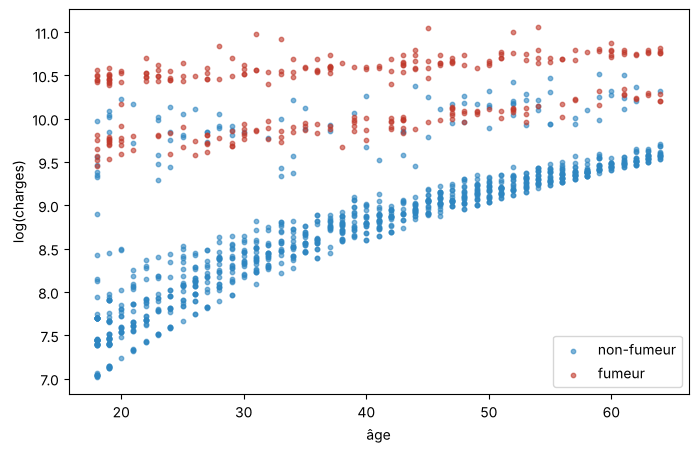

In [10]:
df["log_charges"] = np.log(df.charges)

fig, ax = plt.subplots(figsize=(8, 5))
for fumeur, couleur, nom in [("no", NON_FUMEUR, "non-fumeur"), ("yes", FUMEUR, "fumeur")]:
    d = df[df.smoker == fumeur]
    ax.scatter(d.age, d.log_charges, s=10, alpha=0.6, color=couleur, label=nom)
ax.set_xlabel("âge"); ax.set_ylabel("log(charges)"); ax.legend(loc="lower right")
plt.show()

Le graphique explique les deux résultats précédents :

- les fumeurs ne forment pas un seul nuage mais **deux bandes** presque horizontales ;
- les non-fumeurs forment une bande bien nette qui monte avec l'âge, mais une partie d'entre eux se
  retrouve **au milieu**, entre les bandes : c'est ce bruit qui faisait chuter le R².

D'où la régression triple : une régression par nuage, en écartant le bruit.

### Séparer les trois profils

On trace deux frontières sur le graphique. Elles sont horizontales jusqu'à 56 ans, puis montent un
peu pour suivre les bandes :

- une frontière à 10,2 qui sépare les deux bandes de fumeurs ;
- une frontière à 9,45 qui marque le haut de la bande des non-fumeurs.

Les non-fumeurs situés entre les deux frontières forment le bruit.

profil
non-fumeurs          983
fumeurs, IMC ≥ 30    150
fumeurs, IMC < 30    124
bruit                 80
Name: count, dtype: int64


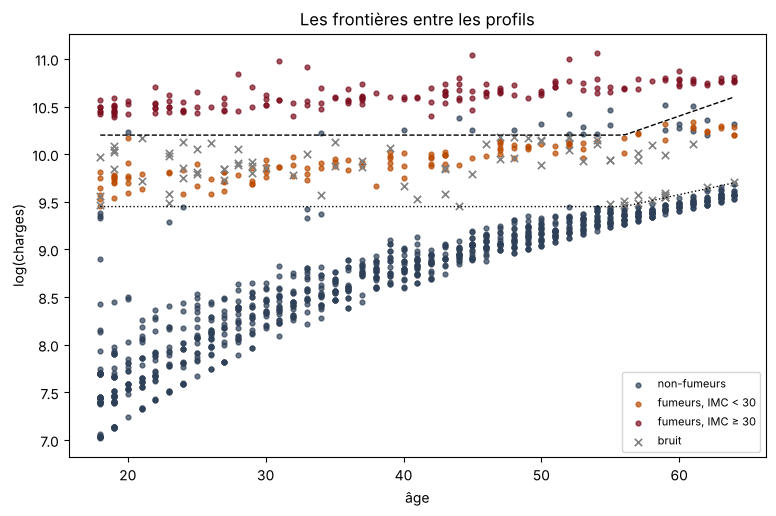

In [11]:
pente = np.clip((df.age - 56) / (64 - 56), 0, 1)        # 0 avant 56 ans, 1 à 64 ans
frontiere_fumeurs = 10.2 + 0.4 * pente
frontiere_basse = 9.45 + 0.25 * pente

fumeur = df.fumeur == 1
df["profil"] = "non-fumeurs"
df.loc[fumeur & (df.log_charges < frontiere_fumeurs), "profil"] = "fumeurs, IMC < 30"
df.loc[fumeur & (df.log_charges >= frontiere_fumeurs), "profil"] = "fumeurs, IMC ≥ 30"
df.loc[~fumeur & (df.log_charges >= frontiere_basse) & (df.log_charges <= 10.2), "profil"] = "bruit"

PROFILS = ["non-fumeurs", "fumeurs, IMC < 30", "fumeurs, IMC ≥ 30"]
COULEURS = {"non-fumeurs": "#2E4057", "fumeurs, IMC < 30": "#B94A00", "fumeurs, IMC ≥ 30": "#7B0D1E"}
print(df.profil.value_counts())

fig, ax = plt.subplots(figsize=(9, 5.5))
for p in PROFILS:
    d = df[df.profil == p]
    ax.scatter(d.age, d.log_charges, s=12, alpha=0.7, color=COULEURS[p], label=p)
bruit = df[df.profil == "bruit"]
ax.scatter(bruit.age, bruit.log_charges, s=28, marker="x", color="gray", lw=1.2, label="bruit")
ages = np.linspace(18, 64, 100)
ax.plot(ages, 10.2 + 0.4 * np.clip((ages - 56) / 8, 0, 1), "k--", lw=1)
ax.plot(ages, 9.45 + 0.25 * np.clip((ages - 56) / 8, 0, 1), "k:", lw=1)
ax.set_xlabel("âge"); ax.set_ylabel("log(charges)")
ax.set_title("Les frontières entre les profils")
ax.legend(fontsize=8, loc="lower right")
plt.show()

Les deux bandes de fumeurs ont été séparées à l'œil. On vérifie qu'elles correspondent bien à
l'obésité :

In [12]:
fumeurs = df[fumeur]
print(pd.crosstab(fumeurs.profil, fumeurs.obese.map({0: "IMC < 30", 1: "IMC ≥ 30"})))

obese              IMC < 30  IMC ≥ 30
profil                               
fumeurs, IMC < 30       123         1
fumeurs, IMC ≥ 30         6       144


La bande du haut est bien celle des fumeurs obèses : sur 274 fumeurs, seuls 7 ne sont pas du côté
attendu.

Le bruit, lui, ne se distingue des autres non-fumeurs par aucune variable :

In [13]:
non_fumeurs = df[~fumeur]
comparaison = non_fumeurs.groupby(non_fumeurs.profil == "bruit")[["age", "bmi", "children", "charges"]].mean().round(1)
comparaison.index = ["non-fumeurs (bande du bas)", "bruit"]
print(comparaison)
print(f"\nbruit : {len(bruit)} assurés, soit {len(bruit) / len(df):.1%} des données")

                             age   bmi  children  charges
non-fumeurs (bande du bas)  39.3  30.6       1.1   7534.8
bruit                       40.2  30.8       1.5  19571.0

bruit : 80 assurés, soit 6.0% des données


Même âge, même IMC, à peine plus d'enfants, et pourtant des charges 2,6 fois plus élevées. Rien
dans les données ne l'explique, on écarte donc ces 80 assurés. Il reste trois profils épurés :

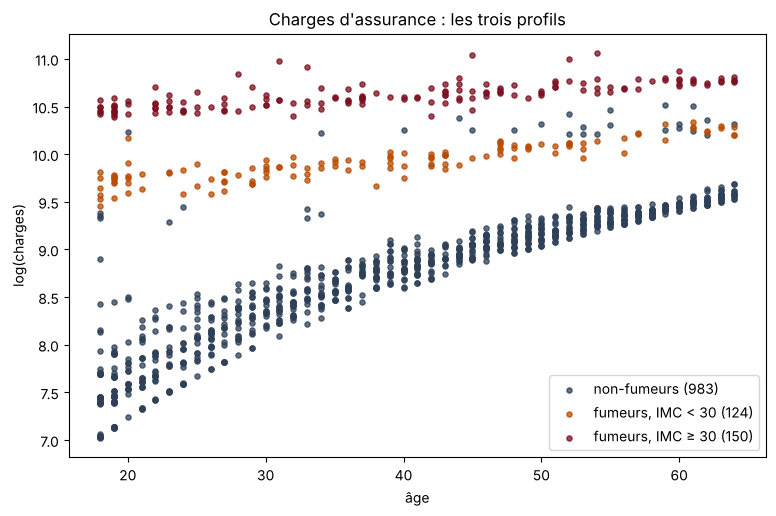

In [14]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for p in PROFILS:
    d = df[df.profil == p]
    ax.scatter(d.age, d.log_charges, s=14, alpha=0.75, color=COULEURS[p], label=f"{p} ({len(d)})")
ax.set_xlabel("âge"); ax.set_ylabel("log(charges)")
ax.set_title("Charges d'assurance : les trois profils")
ax.legend(loc="lower right")
plt.savefig("figures/trois_profils.png", dpi=150, bbox_inches="tight")
plt.show()

### Une régression par profil

Pour chaque profil, on explique $\log(\text{charges})$ par l'âge, le sexe, l'IMC, le nombre
d'enfants et la région. Cette fois, chaque modèle est appris sur 80 % des assurés du profil et
évalué sur les 20 % restants, qu'il n'a jamais vus.

non-fumeurs        : R² sur le test = 0.94   (983 assurés)
fumeurs, IMC < 30  : R² sur le test = 0.98   (124 assurés)
fumeurs, IMC ≥ 30  : R² sur le test = 0.90   (150 assurés)


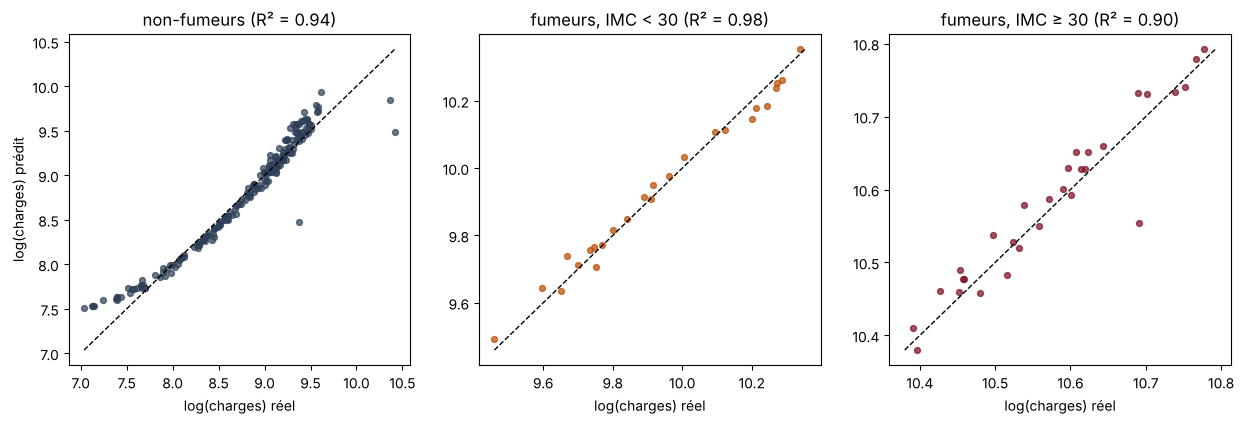

In [15]:
def regression(donnees, variables, cible):
    X = matrice(donnees, variables)
    X_train, X_test, y_train, y_test = train_test_split(X, donnees[cible], test_size=0.2, random_state=42)
    modele = LinearRegression().fit(X_train, y_train)
    return modele, X.columns, y_test, modele.predict(X_test)


modeles, tests = {}, {}
for p in PROFILS:
    donnees = df[df.profil == p]
    modele, colonnes, y_test, y_pred = regression(donnees, ["age", "sex", "bmi", "children", "region"], "log_charges")
    modeles[p], tests[p] = (modele, colonnes), (y_test, y_pred)
    print(f"{p:18s} : R² sur le test = {r2_score(y_test, y_pred):.2f}   ({len(donnees)} assurés)")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, p in zip(axes, PROFILS):
    y_test, y_pred = tests[p]
    ax.scatter(y_test, y_pred, s=18, alpha=0.7, color=COULEURS[p])
    lim = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set_title(f"{p} (R² = {r2_score(y_test, y_pred):.2f})")
    ax.set_xlabel("log(charges) réel")
axes[0].set_ylabel("log(charges) prédit")
plt.savefig("figures/reel_vs_predit.png", dpi=150, bbox_inches="tight")
plt.show()

Chaque profil est bien décrit par sa propre droite : les points se rangent le long de la diagonale.

### Le poids de chaque variable

In [16]:
for p in PROFILS:
    modele, colonnes = modeles[p]
    poids = pd.Series(modele.coef_, index=colonnes).sort_values(ascending=False).round(4)
    print(f"--- {p} (constante {modele.intercept_:.3f})")
    print(poids.to_string(), "\n")

--- non-fumeurs (constante 6.922)
children            0.1350
age                 0.0451
bmi                -0.0001
region_northwest   -0.0470
sex_male           -0.0965
region_southeast   -0.1270
region_southwest   -0.1481 

--- fumeurs, IMC < 30 (constante 8.881)
bmi                 0.0232
children            0.0197
age                 0.0116
region_northwest    0.0099
region_southeast    0.0074
region_southwest    0.0051
sex_male           -0.0400 

--- fumeurs, IMC ≥ 30 (constante 9.914)
region_northwest    0.0161
bmi                 0.0131
age                 0.0067
children            0.0013
region_southwest   -0.0064
region_southeast   -0.0127
sex_male           -0.0141 


Comme la cible est un logarithme, un coefficient se lit comme un pourcentage : 0,045 pour l'âge
veut dire environ +4,5 % de charges par année.

- **Non-fumeurs** : l'âge (+4,5 % par an) et les enfants (environ +13,5 % par enfant) comptent le
  plus, puis le sexe et la région. L'IMC ne joue pas.
- **Fumeurs** : l'âge pèse beaucoup moins (autour de +1 % par an) et c'est l'IMC qui ressort.

### Prédire pour un nouvel assuré

On choisit le modèle d'après le profil (non-fumeur, fumeur avec un IMC inférieur à 30, fumeur avec
un IMC d'au moins 30), puis on repasse en dollars avec l'exponentielle.

In [17]:
def predire(age, sex, bmi, children, smoker, region):
    if smoker == "no":
        profil = "non-fumeurs"
    elif bmi < 30:
        profil = "fumeurs, IMC < 30"
    else:
        profil = "fumeurs, IMC ≥ 30"
    modele, colonnes = modeles[profil]
    assure = pd.DataFrame([{"age": age, "sex": sex, "bmi": bmi, "children": children, "region": region}])
    x = pd.get_dummies(assure).reindex(columns=colonnes, fill_value=0).astype(float)
    return profil, np.exp(modele.predict(x)[0])


for assure in [(45, "female", 32.0, 2, "no", "northwest"),
               (35, "male", 26.5, 1, "yes", "southwest"),
               (40, "female", 35.5, 1, "yes", "southeast")]:
    profil, charges = predire(*assure)
    print(f"{assure} -> {profil} : {charges:,.0f} $")

(45, 'female', 32.0, 2, 'no', 'northwest') -> non-fumeurs : 9,632 $
(35, 'male', 26.5, 1, 'yes', 'southwest') -> fumeurs, IMC < 30 : 19,727 $
(40, 'female', 35.5, 1, 'yes', 'southeast') -> fumeurs, IMC ≥ 30 : 41,583 $


## Bilan

- Le tabac est le premier facteur de coût, et chez les fumeurs l'obésité double encore la facture.
- **Régression double** (en dollars) : correcte pour les fumeurs avec l'âge et l'IMC (R² = 0,75),
  insuffisante pour les non-fumeurs avec l'âge, les enfants et le sexe (R² = 0,41).
- **Régression triple** (en logarithme) : les charges se rangent en trois nuages selon l'âge
  (non-fumeurs, fumeurs, fumeurs obèses), et une régression par nuage les décrit très bien :
  R² de 0,94, 0,98 et 0,90 sur des assurés que les modèles n'avaient pas vus.
- 80 non-fumeurs (6 % des données) ont des charges très élevées qu'aucune variable n'explique :
  ils ont été écartés de la régression triple.